# Task 1 — Multimodal Classification

Notebook presentasi Task 1 untuk menjalankan ulang inferensi dari tiga bobot final.

**Target demonstrasi:** menghitung kembali Macro-F1 pada 9.600 data validasi (sekitar **0,7507**) dan membandingkan seluruh prediksi pada 16.000 data uji dengan `prediksi_klasifikasi.csv`.

Notebook ini menggunakan paket khusus **`Task_1_Klasifikasi.zip`**, bukan paket gabungan Task 1–3.

## 0. Siapkan folder di Google Drive

Buat folder `UTS_Deep_Learning_Task1` di MyDrive dengan susunan:

```text
MyDrive/
└── UTS_Deep_Learning_Task1/
    ├── Task_1_Klasifikasi.zip
    └── data/
        ├── klasifikasi_train.npz
        ├── klasifikasi_train_meta.csv
        ├── klasifikasi_test.npz
        └── klasifikasi_test_meta.csv
```

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
from pathlib import Path
import zipfile
import shutil
import sys
import subprocess
import os

DRIVE_ROOT = Path('/content/drive/MyDrive/UTS_Deep_Learning_Task1')
PROJECT_ZIP = DRIVE_ROOT / 'Task_1_Klasifikasi.zip'
DRIVE_DATA = DRIVE_ROOT / 'data'

PROJECT_DIR = Path('/content/Task1_Klasifikasi')
DATA_DIR = PROJECT_DIR / 'data'

assert PROJECT_ZIP.exists(), f'ZIP tidak ditemukan: {PROJECT_ZIP}'
assert DRIVE_DATA.exists(), f'Folder data tidak ditemukan: {DRIVE_DATA}'

print('Paket Task 1:', PROJECT_ZIP)
print('Folder dataset:', DRIVE_DATA)

Paket Task 1: /content/drive/MyDrive/UTS_Deep_Learning_Task1/Task_1_Klasifikasi.zip
Folder dataset: /content/drive/MyDrive/UTS_Deep_Learning_Task1/data


## 1. Ekstrak paket Task 1 dan salin dataset

Paket diekstrak ke penyimpanan sementara Colab. Dataset dari Google Drive kemudian disalin ke folder `data/` di dalam proyek.

In [5]:
if PROJECT_DIR.exists():
    shutil.rmtree(PROJECT_DIR)
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(PROJECT_ZIP, 'r') as zf:
    zf.extractall(PROJECT_DIR)

DATA_DIR.mkdir(parents=True, exist_ok=True)

required = [
    ('klasifikasi_train', 'npz'),
    ('klasifikasi_train_meta', 'csv'),
    ('klasifikasi_test', 'npz'),
    ('klasifikasi_test_meta', 'csv'),
]

copied = []
for stem, ext in required:
    candidates = [
        DRIVE_DATA / f'{stem}.{ext}',
        DRIVE_DATA / f'{stem}(1).{ext}',
    ]
    src = next((p for p in candidates if p.exists()), None)
    if src is None:
        raise FileNotFoundError(
            f'File {stem}.{ext} tidak ditemukan di {DRIVE_DATA}. '
            'Periksa kembali nama dan lokasi file.'
        )
    dst = DATA_DIR / src.name
    shutil.copy2(src, dst)
    copied.append(dst)

print('Dataset berhasil disiapkan:')
for p in copied:
    print(f'- {p.name}: {p.stat().st_size:,} bytes')

print('\nIsi folder proyek:', sorted(p.name for p in PROJECT_DIR.iterdir()))

Dataset berhasil disiapkan:
- klasifikasi_train.npz: 179,291,087 bytes
- klasifikasi_train_meta.csv: 1,817,688 bytes
- klasifikasi_test.npz: 61,101,197 bytes
- klasifikasi_test_meta.csv: 479,547 bytes

Isi folder proyek: ['Laporan_Task_1.pdf', 'data', 'hasil', 'kode', 'prediksi_klasifikasi.csv']


## 2. Instal dependensi pendukung

PyTorch bawaan Colab dipertahankan. Kita hanya memasang pustaka pendukung yang digunakan kode Task 1.

In [6]:
%pip -q install pandas scipy scikit-learn matplotlib

In [7]:
import torch
import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib

print('PyTorch:', torch.__version__)
print('CUDA tersedia:', torch.cuda.is_available())
print('NumPy:', np.__version__)
print('Pandas:', pd.__version__)
print('SciPy:', scipy.__version__)
print('Scikit-learn:', sklearn.__version__)

PyTorch: 2.14.1+cu130
CUDA tersedia: True
NumPy: 2.4.6
Pandas: 2.2.3
SciPy: 1.16.3
Scikit-learn: 1.6.1


## 3. Periksa kode dan tiga bobot final

Paket Task 1 menyimpan bobot pada `hasil/bobot_42.pt`, `hasil/bobot_123.pt`, dan `hasil/bobot_2026.pt`. Lokasi ini sudah sesuai dengan yang dibaca oleh mode `--cek-bobot`.

In [8]:
TASK1_CODE = PROJECT_DIR / 'kode' / 'task1.py'
DATA_CODE = PROJECT_DIR / 'kode' / 'data_task1.py'
RESULTS_DIR = PROJECT_DIR / 'hasil'
REFERENCE_CSV = PROJECT_DIR / 'prediksi_klasifikasi.csv'

assert TASK1_CODE.exists(), f'Kode utama tidak ditemukan: {TASK1_CODE}'
assert DATA_CODE.exists(), f'Kode preprocessing tidak ditemukan: {DATA_CODE}'
assert REFERENCE_CSV.exists(), f'CSV submission tidak ditemukan: {REFERENCE_CSV}'

for seed in (42, 123, 2026):
    weight = RESULTS_DIR / f'bobot_{seed}.pt'
    assert weight.exists(), f'Bobot tidak ditemukan: {weight}'
    print('Bobot tersedia:', weight.name)

print('Kode utama:', TASK1_CODE)
print('CSV referensi:', REFERENCE_CSV)

Bobot tersedia: bobot_42.pt
Bobot tersedia: bobot_123.pt
Bobot tersedia: bobot_2026.pt
Kode utama: /content/Task1_Klasifikasi/kode/task1.py
CSV referensi: /content/Task1_Klasifikasi/prediksi_klasifikasi.csv


## 4. Reproduksi Macro-F1 validasi — cell utama presentasi

Cell ini menjalankan kode asli `task1.py` dengan opsi `--cek-bobot`.

Program akan:
1. Membaca data train dan test.
2. Membuat ulang feature maps citra dan sensor.
3. Membentuk split validasi dengan seed yang sama.
4. Menghitung ulang standardisasi dari subset training.
5. Memuat tiga bobot final.
6. Menghasilkan probabilitas ketiga model pada validasi dan test.
7. Merata-ratakan probabilitas tiga model.
8. Menghitung Macro-F1 validasi.
9. Memeriksa bahwa seluruh prediksi test identik dengan CSV submission.

Untuk konsistensi dengan eksperimen awal, demonstrasi diarahkan ke CPU dengan dua thread.

In [9]:
cmd = [
    sys.executable,
    str(TASK1_CODE),
    '--data', str(DATA_DIR),
    '--output', str(PROJECT_DIR),
    '--cek-bobot',
    '--device', 'cpu',
]

print('Perintah yang dijalankan:')
print(' '.join(cmd))
subprocess.run(cmd, cwd=PROJECT_DIR, check=True)

Perintah yang dijalankan:
/usr/bin/python3 /content/Task1_Klasifikasi/kode/task1.py --data /content/Task1_Klasifikasi/data --output /content/Task1_Klasifikasi --cek-bobot --device cpu


CompletedProcess(args=['/usr/bin/python3', '/content/Task1_Klasifikasi/kode/task1.py', '--data', '/content/Task1_Klasifikasi/data', '--output', '/content/Task1_Klasifikasi', '--cek-bobot', '--device', 'cpu'], returncode=0)

## 5. Tampilkan CSV submission dan distribusi prediksi

In [10]:
submission = pd.read_csv(REFERENCE_CSV)

print('Jumlah prediksi:', len(submission))
print('Kolom:', submission.columns.tolist())
display(submission.head(10))

print('Distribusi kelas prediksi:')
display(submission['kelas'].value_counts().rename_axis('kelas').to_frame('jumlah'))

Jumlah prediksi: 16000
Kolom: ['id_unit', 'kelas']


,id_unit,kelas
0,U412019,gores
1,U929275,normal
2,U845264,normal
3,U382231,normal
4,U156089,gores
5,U563952,normal
6,U922240,normal
7,U494185,normal
8,U489550,las_dingin
9,U853085,retak


Distribusi kelas prediksi:


,jumlah
kelas,
normal,8874
noda,1660
gores,1495
las_dingin,1331
gelembung,1030
retak,996
kontaminasi,614


## 6. Tampilkan metrik eksperimen dan hasil per lini

In [11]:
metrics_path = RESULTS_DIR / 'metrik.csv'
metrics = pd.read_csv(metrics_path)

print('Hasil ensemble keseluruhan:')
display(
    metrics[
        (metrics['model'] == 'ensemble') &
        (metrics['kelompok'] == 'semua')
    ]
)

print('Hasil ensemble berdasarkan lini:')
display(
    metrics[
        (metrics['model'] == 'ensemble') &
        (metrics['kelompok'].isin(['A', 'B']))
    ][['kelompok', 'n', 'macro_f1']]
)

Hasil ensemble keseluruhan:


,model,seed,kelompok,n,macro_f1,normal,gores,noda,retak,gelembung,las_dingin,kontaminasi
48,ensemble,0,semua,9600,0.750697,0.849383,0.567621,0.815748,0.54902,0.752608,0.943754,0.776744


Hasil ensemble berdasarkan lini:


,kelompok,n,macro_f1
49,A,7193,0.790033
50,B,2407,0.635516


## 7. Tampilkan kurva training dan confusion matrix

Gunakan hasil ini untuk menjelaskan performa model dan pola kesalahan klasifikasi.

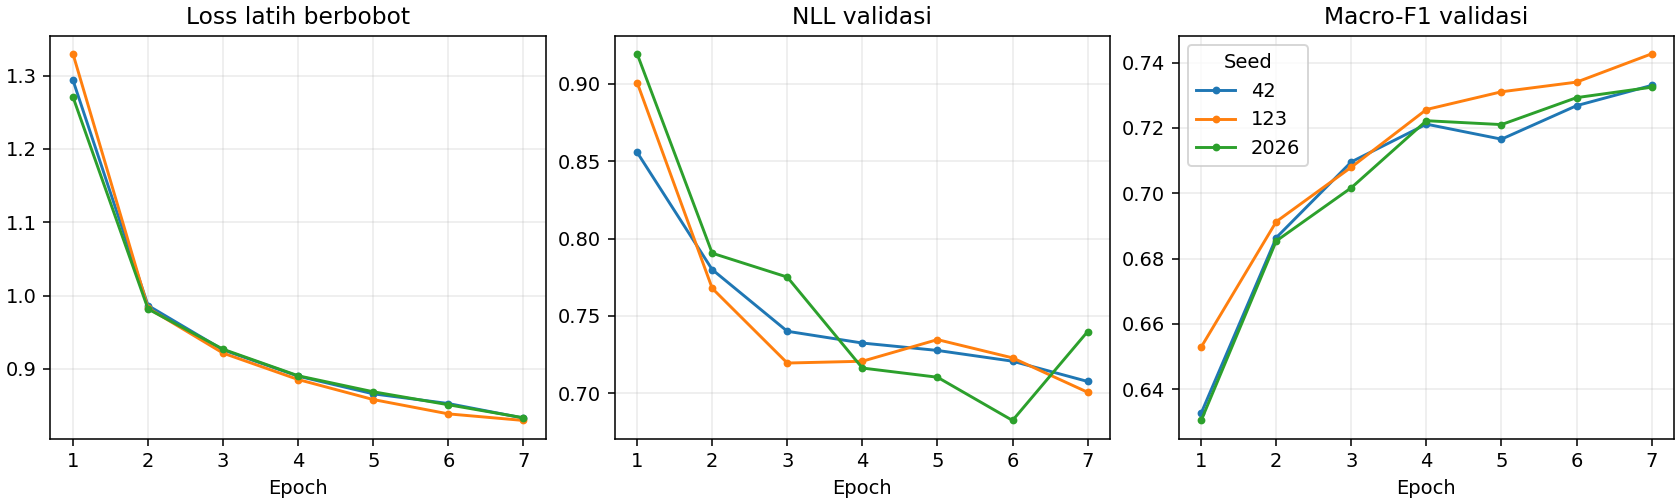

In [12]:
from IPython.display import display, Image

curve_path = RESULTS_DIR / 'kurva.png'
if curve_path.exists():
    display(Image(filename=str(curve_path), width=900))
else:
    print('Kurva tidak ditemukan:', curve_path)

In [13]:
confusion_path = RESULTS_DIR / 'confusion.csv'
confusion = pd.read_csv(confusion_path, index_col=0)
display(confusion)

,normal,gores,noda,retak,gelembung,las_dingin,kontaminasi
label_inspektur,,,,,,,
normal,4269,154,50,150,120,27,8
gores,402,575,53,56,0,0,38
noda,101,26,777,17,31,0,3
retak,276,61,14,364,0,0,6
gelembung,125,11,44,1,505,0,0
las_dingin,59,4,3,2,0,797,0
kontaminasi,42,71,9,15,0,0,334
